In [1]:
from backend.utils.gmsh_function import *
from backend.utils.file_path import *
from backend.src.radiation_algorithm.radiation_algorithm import *

from loop_antenna_mesh import create_loop_antenna_mesh

from backend.cma.cma_algorithm import cma_algorithm
from backend.cma.cma_frequency_sweep import cma_frequency_sweep
from backend.cma.modal_current import ModalCurrent
from backend.cma.modal_farfield import compute_modal_farfield
from backend.cma.modal_visualizer import ModalVisualizer
from backend.cma.modal_significance import modal_significance

In [2]:
name = "loop_antenna_from_AToM_pixelGrid"
path = setup_save_file_paths(name)

In [3]:
# 1. Eigenvalues over a frequency range
n_modes_cma = 6

freq_start_cma = 100e6
freq_stop_cma = 300e6

sweep_data = cma_frequency_sweep(path, freq_start_cma, freq_stop_cma, n_points=11, n_modes=n_modes_cma)

Mesh ready: 96 points, 128 triangles, 160 edges

Assembling Z(f) for 11 frequencies (160x160 edges) on GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) -- geometry reused across the whole sweep...
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (160x160 edges, 11 frequencies).
Z(f) assembly done in 2.5 s (0.223 s/frequency amortised)

Step 1/11 |   100.00 MHz | lambda: -2.776, -3.246, 3.955, 4.284, 5.525, 5.575


d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=4.21e-05 (R's smallest eigenvalue was -4.21e-05). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)
d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=6.06e-05 (R's smallest eigenvalue was -6.06e-05). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)


Step 2/11 |   120.00 MHz | lambda: -2.312, -2.675, 3.287, 3.563, 4.594, 4.644
Step 3/11 |   140.00 MHz | lambda: -1.980, -2.246, 2.809, 3.047, 3.928, 3.978


d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=8.25e-05 (R's smallest eigenvalue was -8.25e-05). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)
d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=1.08e-04 (R's smallest eigenvalue was -1.08e-04). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)


Step 4/11 |   160.00 MHz | lambda: -1.729, -1.880, 2.449, 2.659, 3.427, 3.478


d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=1.36e-04 (R's smallest eigenvalue was -1.36e-04). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)


... (9 outputs left out)

d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=3.30e-04 (R's smallest eigenvalue was -3.30e-04). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)


Step 10/11 |   280.00 MHz | lambda: 0.066, 0.146, -0.947, -1.315, 1.356, 1.490


d:\phd_fahdilou_leat\projets_github\antenna_solver_mom\backend\cma\cma_frequency_sweep.py:151: UserWarning: CMA: large regularization eps_adapt=3.79e-04 (R's smallest eigenvalue was -3.79e-04). R may be poorly conditioned -- check mesh quality, or the structure may be too electrically small at this frequency for a meaningful CMA (most basis functions barely radiate at low ka).
  eigenvalues, eigenvectors, _sort_order = GeneralizedEigenSolver.solve(R, X, params)


Step 11/11 |   300.00 MHz | lambda: 0.265, 0.842, -0.868, -1.224, 1.257, 1.392

Sweep complete. CMA results for 6 modes saved to: data/antennas_cma\loop_antenna_from_AToM_pixelGrid_cma_sweep.mat


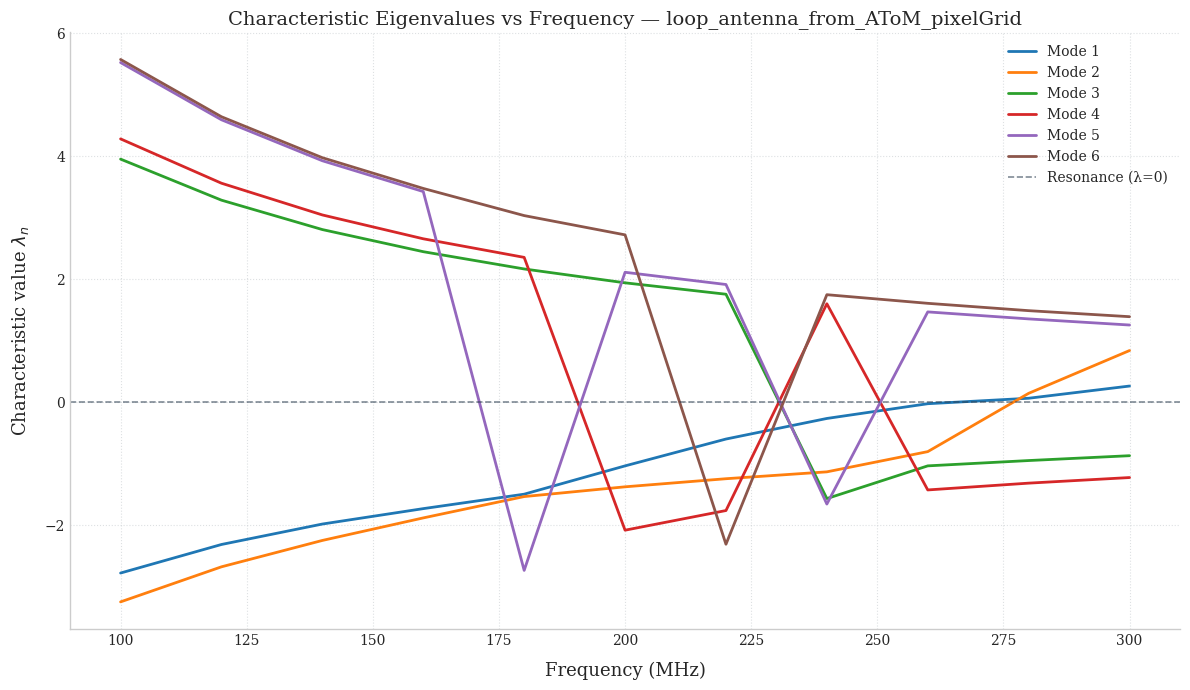

In [4]:
# 2. Eigenvalue curve for the first 6 modes
ModalVisualizer.plot_eigenvalues_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

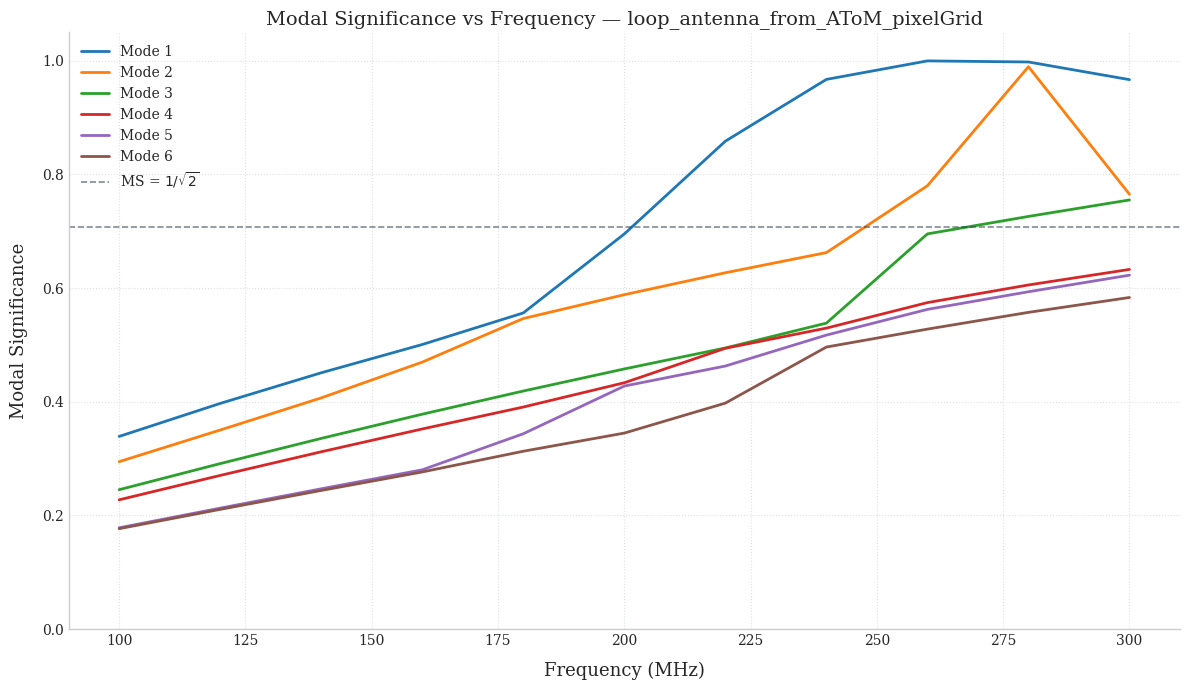

In [5]:
# 3. Modal Significance for the first 6 modes
ModalVisualizer.plot_modal_significance(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

## Diagnostic : cohérence numérique de la matrice Z à 200 MHz

Le sweep ci-dessus a besoin d'une régularisation de plus en plus grande à chaque fréquence
(`eps_adapt` croissant, R negatif de plus en plus loin de 0) -- pas juste du bruit flottant
ponctuel. Avant d'aller plus loin, on vérifie directement la matrice Z assemblée à 200 MHz :

1. **Réciprocité** : `max|Z - Z^T| / max|Z|` doit être ~0 (précision machine) -- un MoM de
   Galerkin correct donne toujours une matrice Z parfaitement symétrique.
2. **R = Re(Z) semi-définie positive** : `min eig(R)` doit être ~0 aux erreurs numériques
   près -- cohérent avec une structure PEC sans perte (puissance rayonnée toujours >= 0).

In [ ]:
from backend.rwg.rwg2 import DataManager_rwg2
from backend.rwg.rwg3 import calculate_z_matrice
from backend.cma.z_matrix_diagnostics import diagnose_z_matrix

points_diag, triangles_diag, edges_diag, _vecteurs_rho_diag = DataManager_rwg2.load_data(path.mat_mesh2)

diag_frequency = 200e6
_omega_diag, _mu_diag, _epsilon_diag, _c_diag, _eta_diag, Z_diag = calculate_z_matrice(
    points_diag, triangles_diag, edges_diag, diag_frequency)

_ = diagnose_z_matrix(Z_diag, frequency=diag_frequency, label=path.name)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (160x160 edges).

Z-matrix diagnostics -- loop_antenna_from_AToM_pixelGrid @ 200.00 MHz
Reciprocity   : max|Z-Z^T| = 2.023e-10  max|Z| = 1.567e+00  -> relative asymmetry = 1.291e-10  [WARNING: not reciprocal]
R = Re(Z) PSD : min eig(R) = -1.684e-04 Ohm  (relative to ||R||_F/N = -2.657e-02)  [WARNING: significantly negative]


: 